<a href="https://colab.research.google.com/github/DannyJung23/ShoreGate/blob/main/notebooks/RF_Independent_Test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Random Forest Independent Testing

## Overview
This notebook evaluates a Random Forest (RF) model trained on the 2018 Palu tsunami dataset by applying it to labelled satellite imagery from the 2018 Sunda Strait tsunami.

The purpose is to assess whether the model can generalise to a separate disaster event that was not used for model training. The trained Palu model is loaded from its saved artifact and applied directly to the Sunda dataset without retraining.

The objective is to evaluate cross-event generalisation using an independent test dataset and quantify the model's ability to identify damaged pixels.

## Workflow
1. Loading the test dataset and the trained model.
2. Validating the inputs.
3. Generating predictions.
4. Evaluating performance.


In [7]:
%pip -q install numpy pandas scikit-learn matplotlib seaborn joblib requests

Download the Sunda dataset and feature schema

In [8]:
from pathlib import Path
import json
import requests
import numpy as np
import pandas as pd

GITHUB_RAW = (
    "https://raw.githubusercontent.com/"
    "DannyJung23/ShoreGate/main"
)

DATASET_URL = (
    f"{GITHUB_RAW}/datasets/sunda_rf_test_dataset.npz"
)

SCHEMA_URL = (
    f"{GITHUB_RAW}/models/shoregate_rf_feature_schema.json"
)

OUTPUT_DIR = Path("/content/shoregate_sunda_test_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATASET_PATH = Path("/content/sunda_rf_test_dataset.npz")
SCHEMA_PATH = Path("/content/shoregate_rf_feature_schema.json")


def download_file(url, destination):
    response = requests.get(url, timeout=300)
    response.raise_for_status()
    destination.write_bytes(response.content)
    print(f"Downloaded: {destination.name}")
    print(f"Size: {destination.stat().st_size / (1024**2):.2f} MB")


download_file(DATASET_URL, DATASET_PATH)
download_file(SCHEMA_URL, SCHEMA_PATH)

with SCHEMA_PATH.open("r", encoding="utf-8") as f:
    schema = json.load(f)

print("\nSchema project:", schema["project"])
print("Training event:", schema["training_event"])
print("Expected feature count:", schema["n_features"])
print("Classification threshold:", schema["classification_threshold"])

Downloaded: sunda_rf_test_dataset.npz
Size: 6.73 MB
Downloaded: shoregate_rf_feature_schema.json
Size: 0.00 MB

Schema project: ShoreGate
Training event: Palu tsunami
Expected feature count: 24
Classification threshold: 0.35


Upload the trained Palu RF model

In [9]:
from google.colab import files

uploaded = files.upload()

MODEL_FILENAME = "shoregate_rf_palu.joblib"

if MODEL_FILENAME not in uploaded:
    raise FileNotFoundError(
        f"Please upload the exact file: {MODEL_FILENAME}"
    )

MODEL_PATH = Path("/content") / MODEL_FILENAME

print("Model uploaded:", MODEL_PATH.name)
print(f"Model size: {MODEL_PATH.stat().st_size / (1024**3):.2f} GB")

Saving shoregate_rf_palu.joblib to shoregate_rf_palu.joblib
Model uploaded: shoregate_rf_palu.joblib
Model size: 1.01 GB


Load and validate the test dataset

In [10]:
with np.load(DATASET_PATH, allow_pickle=False) as data:
    X_sunda = data["X"]
    y_sunda = data["y"]
    patch_ids_sunda = data["patch_ids"]
    feature_names_sunda = data["feature_names"].tolist()

print("X shape:", X_sunda.shape)
print("y shape:", y_sunda.shape)
print("Unique patches:", len(np.unique(patch_ids_sunda)))
print("Feature count:", len(feature_names_sunda))
print("Labels:", np.unique(y_sunda))
print("All features finite:", np.isfinite(X_sunda).all())

print("\nReference class counts:")
print("Intact:", int(np.sum(y_sunda == 0)))
print("Damaged:", int(np.sum(y_sunda == 1)))

assert X_sunda.shape == (111941, 24)
assert y_sunda.shape == (111941,)
assert len(X_sunda) == len(y_sunda) == len(patch_ids_sunda)
assert len(np.unique(patch_ids_sunda)) == 93
assert len(feature_names_sunda) == 24
assert np.isfinite(X_sunda).all()
assert np.array_equal(np.unique(y_sunda), [0, 1])

print("\nDataset integrity checks passed.")

X shape: (111941, 24)
y shape: (111941,)
Unique patches: 93
Feature count: 24
Labels: [0 1]
All features finite: True

Reference class counts:
Intact: 110405
Damaged: 1536

Dataset integrity checks passed.


Load and validate the RF model and feature schema

In [11]:
import joblib

rf_model = joblib.load(MODEL_PATH)

expected_features = schema["feature_names"]

print("Model type:", type(rf_model).__name__)
print("Model feature count:", rf_model.n_features_in_)
print("Schema feature count:", schema["n_features"])
print("Sunda feature count:", X_sunda.shape[1])
print("Feature order matches:", feature_names_sunda == expected_features)
print("Model classes:", rf_model.classes_)

assert type(rf_model).__name__ == "RandomForestClassifier"
assert rf_model.n_features_in_ == 24
assert schema["n_features"] == 24
assert feature_names_sunda == expected_features
assert np.array_equal(rf_model.classes_, [0, 1])
assert schema["training_event"] == "Palu tsunami"

THRESHOLD = float(schema["classification_threshold"])

assert np.isclose(THRESHOLD, 0.35)

print("\nModel and feature schema validation passed.")
print("Fixed classification threshold:", THRESHOLD)

Model type: RandomForestClassifier
Model feature count: 24
Schema feature count: 24
Sunda feature count: 24
Feature order matches: True
Model classes: [0 1]

Model and feature schema validation passed.
Fixed classification threshold: 0.35


### Model Testing on Sunda

In [12]:
# Predict damaged-class probabilities.
damaged_prob_sunda = rf_model.predict_proba(X_sunda)[:, 1]

# Convert probabilities into binary predictions.
y_pred_sunda = (
    damaged_prob_sunda >= THRESHOLD
).astype(np.uint8)

print("Classification threshold:", THRESHOLD)
print("Total samples:", len(y_pred_sunda))
print("Predicted intact:", int(np.sum(y_pred_sunda == 0)))
print("Predicted damaged:", int(np.sum(y_pred_sunda == 1)))
print(
    "Mean damaged probability:",
    round(float(damaged_prob_sunda.mean()), 4)
)

print("\nPrediction generation completed.")

Classification threshold: 0.35
Total samples: 111941
Predicted intact: 107940
Predicted damaged: 4001
Mean damaged probability: 0.1269

Prediction generation completed.


### Performance Evaluation

In [13]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
)

cm = confusion_matrix(
    y_sunda,
    y_pred_sunda,
    labels=[0, 1]
)

accuracy = accuracy_score(y_sunda, y_pred_sunda)
balanced_acc = balanced_accuracy_score(y_sunda, y_pred_sunda)

damaged_precision = precision_score(
    y_sunda, y_pred_sunda, pos_label=1, zero_division=0
)
damaged_recall = recall_score(
    y_sunda, y_pred_sunda, pos_label=1, zero_division=0
)
damaged_f1 = f1_score(
    y_sunda, y_pred_sunda, pos_label=1, zero_division=0
)

average_precision = average_precision_score(
    y_sunda, damaged_prob_sunda
)
roc_auc = roc_auc_score(y_sunda, damaged_prob_sunda)

metrics = {
    "test_event": "Sunda Strait tsunami",
    "training_event": schema["training_event"],
    "n_samples": int(len(y_sunda)),
    "n_patches": int(len(np.unique(patch_ids_sunda))),
    "threshold": THRESHOLD,
    "accuracy": float(accuracy),
    "balanced_accuracy": float(balanced_acc),
    "damaged_precision": float(damaged_precision),
    "damaged_recall": float(damaged_recall),
    "damaged_f1": float(damaged_f1),
    "average_precision": float(average_precision),
    "roc_auc": float(roc_auc),
}

print("Confusion matrix (rows = actual, columns = predicted):")
print("                 Predicted intact  Predicted damaged")
print(f"Actual intact     {cm[0, 0]:>15,}  {cm[0, 1]:>17,}")
print(f"Actual damaged    {cm[1, 0]:>15,}  {cm[1, 1]:>17,}")

print("\nClassification report:")
print(
    classification_report(
        y_sunda,
        y_pred_sunda,
        labels=[0, 1],
        target_names=["Intact", "Damaged"],
        digits=4,
        zero_division=0,
    )
)

print("Additional metrics:")
for name, value in metrics.items():
    if isinstance(value, float):
        print(f"{name}: {value:.4f}")
    else:
        print(f"{name}: {value}")

Confusion matrix (rows = actual, columns = predicted):
                 Predicted intact  Predicted damaged
Actual intact             106,694              3,711
Actual damaged              1,246                290

Classification report:
              precision    recall  f1-score   support

      Intact     0.9885    0.9664    0.9773    110405
     Damaged     0.0725    0.1888    0.1047      1536

    accuracy                         0.9557    111941
   macro avg     0.5305    0.5776    0.5410    111941
weighted avg     0.9759    0.9557    0.9653    111941

Additional metrics:
test_event: Sunda Strait tsunami
training_event: Palu tsunami
n_samples: 111941
n_patches: 93
threshold: 0.3500
accuracy: 0.9557
balanced_accuracy: 0.5776
damaged_precision: 0.0725
damaged_recall: 0.1888
damaged_f1: 0.1047
average_precision: 0.0584
roc_auc: 0.6279


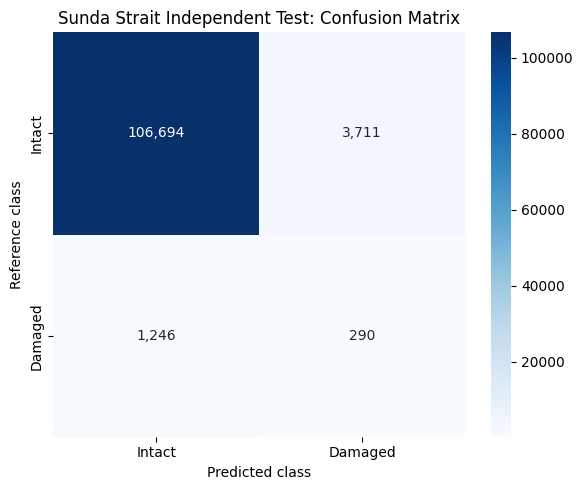

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt=",",
    cmap="Blues",
    xticklabels=["Intact", "Damaged"],
    yticklabels=["Intact", "Damaged"],
    ax=ax,
)

ax.set_title("Sunda Strait Independent Test: Confusion Matrix")
ax.set_xlabel("Predicted class")
ax.set_ylabel("Reference class")

plt.tight_layout()
plt.show()

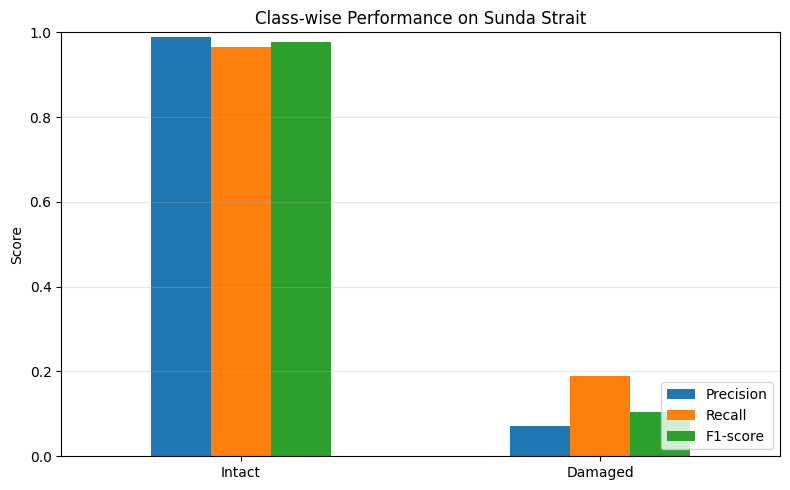

In [15]:
report = classification_report(
    y_sunda,
    y_pred_sunda,
    labels=[0, 1],
    target_names=["Intact", "Damaged"],
    output_dict=True,
    zero_division=0,
)

class_metrics = pd.DataFrame(
    {
        "Class": ["Intact", "Damaged"],
        "Precision": [
            report["Intact"]["precision"],
            report["Damaged"]["precision"],
        ],
        "Recall": [
            report["Intact"]["recall"],
            report["Damaged"]["recall"],
        ],
        "F1-score": [
            report["Intact"]["f1-score"],
            report["Damaged"]["f1-score"],
        ],
    }
).set_index("Class")

ax = class_metrics.plot(
    kind="bar",
    figsize=(8, 5),
    ylim=(0, 1),
    rot=0,
)

ax.set_title("Class-wise Performance on Sunda Strait")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()